# Training Code

In [2]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import joblib
import glob

In [3]:
train_files = sorted(glob.glob("./train_sets/site_*_train.csv"))
df = pd.concat([pd.read_csv(f) for f in train_files], ignore_index=True)

print("Training rows loaded:", len(df))


df = df.sort_values(["year","month","day","hour"]).reset_index(drop=True)
df["datetime"] = pd.to_datetime(df[["year","month","day","hour"]])


df["dayofyear"] = df["datetime"].dt.dayofyear
df["weekday"]   = df["datetime"].dt.weekday
df["is_weekend"] = df["weekday"].isin([5,6]).astype(int)
df["season"]     = (df["month"] % 12) // 3


Training rows loaded: 120172


In [4]:

lags = [1,2,3,6,12,24]

for lag in lags:
    df[f"O3_lag_{lag}"]  = df["O3_target"].shift(lag)
    df[f"NO2_lag_{lag}"] = df["NO2_target"].shift(lag)


df["O3_roll_6"]  = df["O3_target"].rolling(6).mean()
df["O3_roll_12"] = df["O3_target"].rolling(12).mean()
df["O3_roll_24"] = df["O3_target"].rolling(24).mean()

df["NO2_roll_6"]  = df["NO2_target"].rolling(6).mean()
df["NO2_roll_12"] = df["NO2_target"].rolling(12).mean()
df["NO2_roll_24"] = df["NO2_target"].rolling(24).mean()

In [5]:
df["wind_mag"] = np.sqrt(df["u_forecast"]**2 + df["v_forecast"]**2)
df["temp_NO2"] = df["T_forecast"] * df["NO2_forecast"]
df["wind_NO2"] = df["wind_mag"] * df["NO2_forecast"]

In [6]:
df = df.replace([np.inf,-np.inf], np.nan).dropna().reset_index(drop=True)

In [7]:
df = df.replace([np.inf,-np.inf], np.nan).dropna().reset_index(drop=True)

print("Rows after feature creation:", len(df))

features = [
    "O3_forecast","NO2_forecast","T_forecast","q_forecast",
    "u_forecast","v_forecast","w_forecast",
    "NO2_satellite","HCHO_satellite","ratio_satellite",
    "NO2_satellite_missing","HCHO_satellite_missing","ratio_satellite_missing",
    "year","month","day","hour",
    "dayofyear","weekday","is_weekend","season",
    "wind_mag","temp_NO2","wind_NO2",
    "O3_roll_6","O3_roll_12","O3_roll_24",
    "NO2_roll_6","NO2_roll_12","NO2_roll_24"
]

features += [f"O3_lag_{l}" for l in lags]
features += [f"NO2_lag_{l}" for l in lags]

X_train = df[features]
y_train_O3 = df["O3_target"]
y_train_NO2 = df["NO2_target"]


params = {
    "n_estimators": 900,
    "learning_rate": 0.03,
    "max_depth": 9,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_lambda": 2.0,
    "reg_alpha": 1.0,
    "objective": "reg:squarederror",
    "tree_method": "hist"
}

Rows after feature creation: 120148


In [8]:
print("\nTraining O3 model on full training data...")
model_O3 = XGBRegressor(**params)
model_O3.fit(X_train, y_train_O3)
joblib.dump(model_O3, "xgb_O3_improved.pkl")
print("Saved xgb_O3_improved.pkl")

print("\nTraining NO2 model on full training data...")
model_NO2 = XGBRegressor(**params)
model_NO2.fit(X_train, y_train_NO2)
joblib.dump(model_NO2, "xgb_NO2_improved.pkl")
print("Saved xgb_NO2_improved.pkl")



Training O3 model on full training data...
Saved xgb_O3_improved.pkl

Training NO2 model on full training data...
Saved xgb_NO2_improved.pkl



Generating graphs...



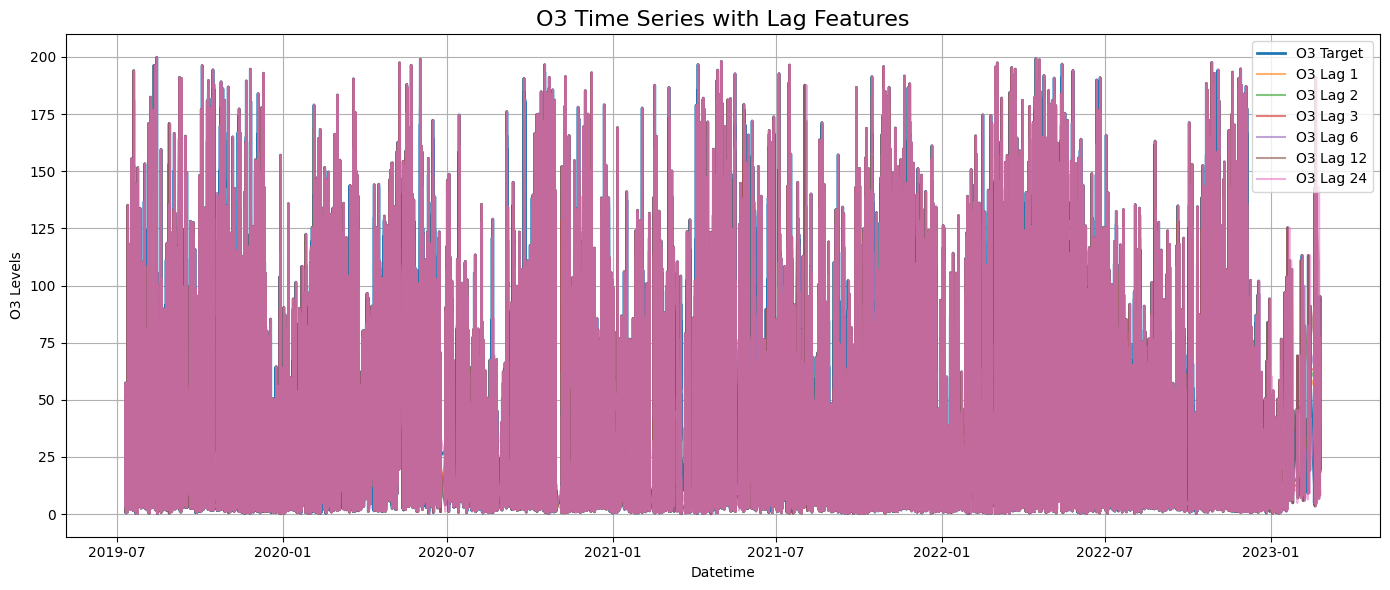

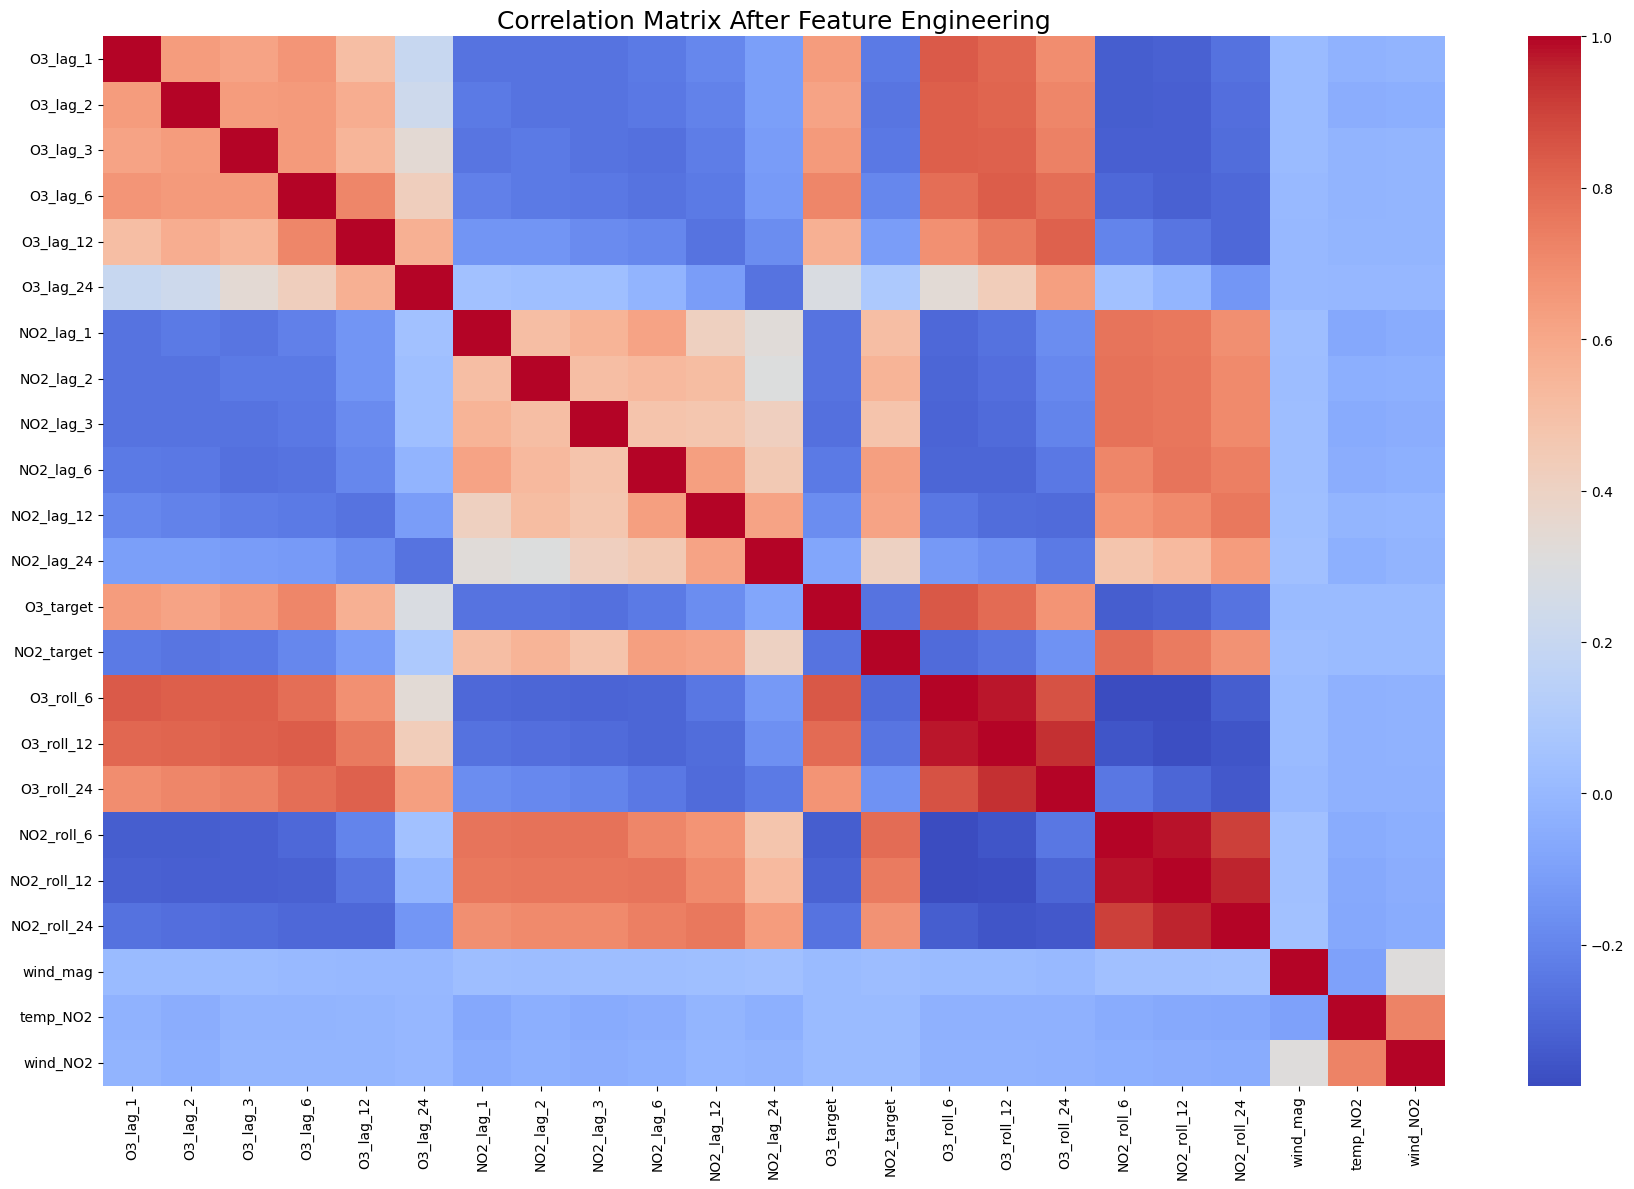

<Figure size 1200x1200 with 0 Axes>

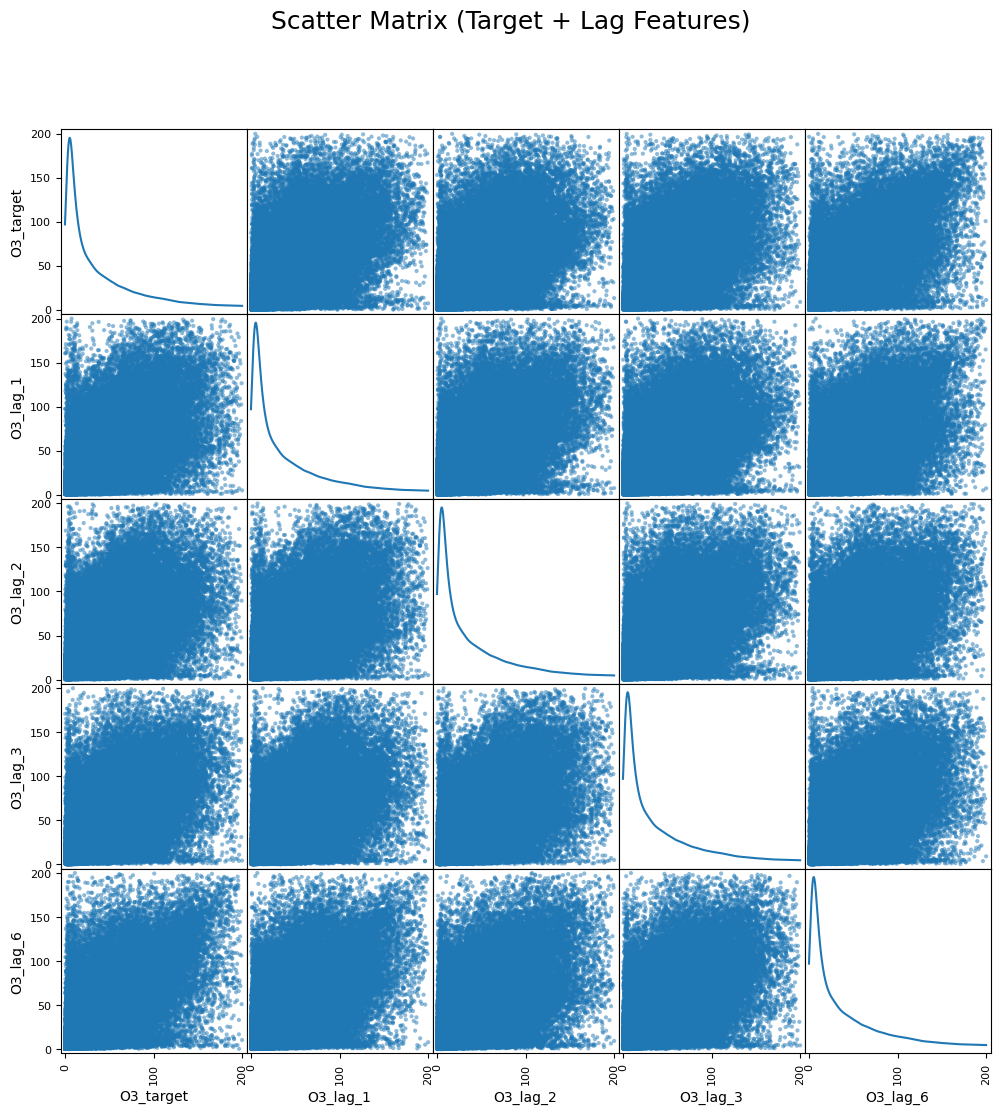


📊 All graphs generated successfully!


In [9]:
# =========================================================
# 📈 11. VISUALIZATION AFTER LAG/ROLLING/INTERACTION FEATURES
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix

print("\nGenerating graphs...\n")

# ---------------------------------------------------------
# 11A. TIME SERIES PLOT (O3 + its lags)
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(df["datetime"], df["O3_target"], label="O3 Target", linewidth=2)
for lag in lags:
    plt.plot(df["datetime"], df[f"O3_lag_{lag}"], label=f"O3 Lag {lag}", alpha=0.6)

plt.title("O3 Time Series with Lag Features", fontsize=16)
plt.xlabel("Datetime")
plt.ylabel("O3 Levels")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 11B. CORRELATION MATRIX HEATMAP
# ---------------------------------------------------------
corr_cols = [f"O3_lag_{l}" for l in lags] + [f"NO2_lag_{l}" for l in lags] + \
            ["O3_target", "NO2_target",
             "O3_roll_6","O3_roll_12","O3_roll_24",
             "NO2_roll_6","NO2_roll_12","NO2_roll_24",
             "wind_mag","temp_NO2","wind_NO2"]

corr_df = df[corr_cols].corr()

plt.figure(figsize=(18, 12))
sns.heatmap(corr_df, cmap="coolwarm", annot=False)
plt.title("Correlation Matrix After Feature Engineering", fontsize=18)
plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 11C. SCATTER MATRIX (PAIRPLOT)
# ---------------------------------------------------------
scatter_cols = ["O3_target"] + [f"O3_lag_{l}" for l in [1,2,3,6]]
plt.figure(figsize=(12, 12))
scatter_matrix(df[scatter_cols], figsize=(12, 12), diagonal='kde')
plt.suptitle("Scatter Matrix (Target + Lag Features)", fontsize=18)
plt.show()

print("\n📊 All graphs generated successfully!")
